# COMP6008 Group 17 – Agent 3: Deep Q-Network (DQN)

**Author:** Marko Koiduste (22563501)

Trains a DQN on the home energy environment, adapted from Practical 8. Environment formulation: `energy_env_formulation.ipynb`.

Smoke run to verify requirements and model.

## 0. Setup
Installs dependencies and writes the environment files so the notebook runs on its own.

In [1]:
!pip install -q gymnasium torch


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%%writefile profiles.py
"""
profiles.py - Synthetic hourly data for the home energy scheduling environment.

Everything here is a 24-value array (one value per hour, index 0 = midnight).
All numbers are illustrative assumptions for a typical Perth household;
state them as assumptions in the report.

Usage:
    from profiles import sample_day
    day = sample_day(rng)          # rng = np.random.default_rng(seed)
    day["solar"], day["load"], day["price"], ...
"""

import numpy as np

HOURS = np.arange(24)

# ---------------------------------------------------------------------------
# Solar generation (kW) - bell curve between sunrise and sunset, scaled by weather
# ---------------------------------------------------------------------------
SOLAR_PEAK_KW = 5.0            # roughly a 6.6 kW rooftop system on a clear day
SUNRISE, SUNSET = 6, 18

WEATHER_TYPES = ["sunny", "cloudy", "rainy"]
WEATHER_PROBS = [0.6, 0.3, 0.1]                          # Perth is mostly sunny
WEATHER_SCALE = {"sunny": 1.0, "cloudy": 0.5, "rainy": 0.2}


def solar_profile(weather, rng=None, noise=0.1):
    """Hourly solar output (kW) for a given weather type."""
    curve = np.zeros(24)
    daylight = (HOURS >= SUNRISE) & (HOURS <= SUNSET)
    # half-sine shape: 0 at sunrise/sunset, peak at midday
    curve[daylight] = np.sin(np.pi * (HOURS[daylight] - SUNRISE) / (SUNSET - SUNRISE))
    solar = SOLAR_PEAK_KW * WEATHER_SCALE[weather] * curve
    if rng is not None:                                   # small random variation
        solar *= 1 + rng.normal(0, noise, 24)
    return np.clip(solar, 0, None)


# ---------------------------------------------------------------------------
# Household base load (kW) - things we do NOT control (fridge, lights, cooking)
# ---------------------------------------------------------------------------
BASE_LOAD = np.array([
    0.4, 0.3, 0.3, 0.3, 0.3, 0.4,    # 00-05 night
    0.8, 1.2, 1.0, 0.6, 0.5, 0.5,    # 06-11 morning peak
    0.6, 0.5, 0.5, 0.6, 0.9, 1.5,    # 12-17 afternoon
    2.0, 1.8, 1.4, 1.0, 0.7, 0.5,    # 18-23 evening peak
])


def load_profile(rng=None, noise=0.1):
    load = BASE_LOAD.copy()
    if rng is not None:
        load *= 1 + rng.normal(0, noise, 24)
    return np.clip(load, 0.1, None)


# ---------------------------------------------------------------------------
# Time-of-use tariff ($/kWh) - cheap midday, expensive evening peak
# ---------------------------------------------------------------------------
PRICE_OFFPEAK, PRICE_MIDDAY, PRICE_PEAK = 0.25, 0.10, 0.55
FEED_IN_PRICE = 0.03            # paid for exporting solar to the grid


def price_profile():
    price = np.full(24, PRICE_OFFPEAK)
    price[9:15] = PRICE_MIDDAY       # 9am-3pm
    price[15:21] = PRICE_PEAK        # 3pm-9pm
    return price


# ---------------------------------------------------------------------------
# Home battery and EV
# ---------------------------------------------------------------------------
BATTERY = {"capacity_kwh": 10.0, "max_rate_kw": 5.0, "efficiency": 0.95}

EV = {
    "capacity_kwh": 60.0,
    "max_rate_kw": 7.0,
    "arrive_hour": 18,          # plugged in from 6pm ...
    "depart_hour": 7,           # ... until 7am next morning
    "arrive_soc": 0.4,          # 40% charge when it gets home
    "target_soc": 0.8,          # needs 80% by departure (penalty if not)
}


def ev_plugged_in():
    """Boolean array: True for hours the EV is at home and can charge."""
    return (HOURS >= EV["arrive_hour"]) | (HOURS < EV["depart_hour"])


# ---------------------------------------------------------------------------
# Shiftable appliances - must run once per day, agent chooses when
# ---------------------------------------------------------------------------
APPLIANCES = {
    "washing_machine": {"power_kw": 1.0, "duration_h": 2, "earliest": 7,  "deadline": 22},
    "dishwasher":      {"power_kw": 1.2, "duration_h": 2, "earliest": 8,  "deadline": 23},
}


# ---------------------------------------------------------------------------
# One episode = one simulated day
# ---------------------------------------------------------------------------
def sample_day(rng, weather=None):
    """Return all profiles for one day. Weather is random unless given."""
    if weather is None:
        weather = rng.choice(WEATHER_TYPES, p=WEATHER_PROBS)
    return {
        "weather": weather,
        "solar": solar_profile(weather, rng),
        "load": load_profile(rng),
        "price": price_profile(),
        "feed_in": FEED_IN_PRICE,
        "ev_plugged_in": ev_plugged_in(),
    }

Overwriting profiles.py


In [3]:
%%writefile energy_env.py
"""
energy_env.py - Home energy scheduling environment (Gymnasium), 17-dim variant.

One episode = one day, 24 hourly steps, from 07:00 to 07:00 the next morning.
Starting at 07:00 means the EV's deadline (charged by 07:00 departure) falls
exactly at the end of the episode.

All physical constants come from profiles.py, so this file and the data
profiles share a single source of truth.

Observation (17 values, fixed order - do not change without telling the group):
    0 hour_sin, 1 hour_cos, 2 battery_soc, 3 ev_soc, 4 ev_plugged_in,
    5 solar_now, 6 solar_next, 7 load_now, 8 price_now, 9 price_next,
    10 sunny, 11 cloudy, 12 rainy, 13 washer_pending, 14 dishwasher_pending,
    15 washer_hours_left, 16 dishwasher_hours_left

Action (Discrete 12):  action = battery * 4 + ev * 2 + appliance
    battery:   0 = charge, 1 = idle, 2 = discharge
    ev:        0 = wait,   1 = charge
    appliance: 0 = defer,  1 = start next pending appliance
"""

import numpy as np
import gymnasium as gym
from gymnasium import spaces

import profiles as P

START_HOUR = 7
EV_PENALTY_PER_KWH = 1.0      # $ per kWh the EV is short at departure
APPLIANCE_PENALTY = 2.0       # $ if an appliance misses its deadline
SOLAR_MAX = 7.5               # observation-space bound on solar (kW)


def decode_action(action):
    """Split the single action number into its three parts."""
    action = int(action)
    return action // 4, (action // 2) % 2, action % 2


class EnergyEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, weather=None):
        super().__init__()
        if weather not in (None, *P.WEATHER_TYPES):
            raise ValueError("weather must be sunny, cloudy or rainy")
        self.fixed_weather = weather          # None = random weather each episode
        self.appliance_names = list(P.APPLIANCES)

        low = np.array([-1, -1] + [0.0] * 15, dtype=np.float32)
        high = np.array([1, 1, 1, 1, 1,
                         SOLAR_MAX, SOLAR_MAX, 5.0,
                         P.PRICE_PEAK, P.PRICE_PEAK,
                         1, 1, 1, 1, 1,
                         2, 2], dtype=np.float32)
        self.observation_space = spaces.Box(low, high, dtype=np.float32)
        self.action_space = spaces.Discrete(12)

    # ------------------------------------------------------------------ reset
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)                    # sets self.np_random
        self.day = P.sample_day(self.np_random, self.fixed_weather)
        self.t = 0                                   # step counter 0..23
        self.battery_soc = 0.5
        self.ev_soc = P.EV["arrive_soc"]
        # per appliance: "pending" (not started), "running", "done", "missed"
        self.app_status = {n: "pending" for n in self.appliance_names}
        self.app_hours_left = {n: 0 for n in self.appliance_names}
        return self._obs(), {}

    # ------------------------------------------------------------------- step
    def step(self, action):
        assert self.action_space.contains(action)
        h = self.hour
        b_act, ev_act, app_act = decode_action(int(action))
        solar = self.day["solar"][h]
        load = self.day["load"][h]
        price = self.day["price"][h]
        penalty = 0.0

        # 1. Appliances: start the next pending one if allowed, then run them
        if app_act == 1:
            for n in self.appliance_names:
                spec = P.APPLIANCES[n]
                if self.app_status[n] == "pending" and h >= spec["earliest"]:
                    self.app_status[n] = "running"
                    self.app_hours_left[n] = spec["duration_h"]
                    break
        appliance_kwh = 0.0
        for n in self.appliance_names:
            if self.app_status[n] == "running":
                appliance_kwh += P.APPLIANCES[n]["power_kw"]
                self.app_hours_left[n] -= 1
                if self.app_hours_left[n] == 0:
                    self.app_status[n] = "done"

        # 2. EV arrives home at 18:00 with a fixed charge level
        if h == P.EV["arrive_hour"]:
            self.ev_soc = P.EV["arrive_soc"]
        ev_kwh = 0.0
        if ev_act == 1 and self.day["ev_plugged_in"][h]:
            ev_kwh = min(P.EV["max_rate_kw"], (1 - self.ev_soc) * P.EV["capacity_kwh"])
            self.ev_soc += ev_kwh / P.EV["capacity_kwh"]

        # 3. Home battery (efficiency loss on the way in and out)
        cap, rate, eff = (P.BATTERY[k] for k in ("capacity_kwh", "max_rate_kw", "efficiency"))
        batt_in = batt_out = 0.0
        if b_act == 0:                                   # charge
            batt_in = min(rate, (1 - self.battery_soc) * cap / eff)
            self.battery_soc += batt_in * eff / cap
        elif b_act == 2:                                 # discharge
            drawn = min(rate, self.battery_soc * cap)
            self.battery_soc -= drawn / cap
            batt_out = drawn * eff
        self.battery_soc = float(np.clip(self.battery_soc, 0, 1))

        # 4. Energy balance: positive = buy from grid, negative = sell
        net = load + appliance_kwh + ev_kwh + batt_in - solar - batt_out
        grid_import, grid_export = max(net, 0.0), max(-net, 0.0)
        cost = grid_import * price - grid_export * self.day["feed_in"]

        # 5. Penalties: appliance past its latest start time
        for n in self.appliance_names:
            spec = P.APPLIANCES[n]
            latest_start = spec["deadline"] - spec["duration_h"]
            if self.app_status[n] == "pending" and h >= latest_start:
                self.app_status[n] = "missed"
                penalty += APPLIANCE_PENALTY

        # 6. Advance time; at 07:00 the EV leaves - penalise any shortfall
        self.t += 1
        terminated = self.t == 24
        shortfall = 0.0
        if terminated:
            shortfall = max(P.EV["target_soc"] - self.ev_soc, 0) * P.EV["capacity_kwh"]
            penalty += EV_PENALTY_PER_KWH * shortfall

        reward = -(cost + penalty)
        info = {"cost": cost, "penalty": penalty, "grid_import": grid_import,
                "grid_export": grid_export, "hour": h, "weather": self.day["weather"],
                "ev_shortfall": shortfall,
                "missed_jobs": sum(1 for n in self.appliance_names
                                   if self.app_status[n] == "missed")}
        return self._obs(), reward, terminated, False, info

    # --------------------------------------------------------------- helpers
    @property
    def hour(self):
        return (START_HOUR + self.t) % 24

    def _obs(self):
        h = self.hour
        nxt = (h + 1) % 24
        weather_onehot = [float(self.day["weather"] == w) for w in P.WEATHER_TYPES]
        pending = [float(self.app_status[n] == "pending") for n in self.appliance_names]
        hours_left = [float(self.app_hours_left[n]) for n in self.appliance_names]
        obs = [
            np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24),
            self.battery_soc, self.ev_soc, float(self.day["ev_plugged_in"][h]),
            self.day["solar"][h], self.day["solar"][nxt], self.day["load"][h],
            self.day["price"][h], self.day["price"][nxt],
            *weather_onehot, *pending, *hours_left,
        ]
        return np.clip(np.array(obs, dtype=np.float32),
                       self.observation_space.low, self.observation_space.high)

Overwriting energy_env.py


In [4]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from collections import deque, namedtuple
from gymnasium import spaces

import profiles as P
from energy_env import EnergyEnv, decode_action

# if GPU is to be used
device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else
    "cpu"
)

## 1. Environment checks
Gymnasium checker, then one random episode printed hour by hour.

In [5]:
import importlib, energy_env
importlib.reload(energy_env)
from energy_env import EnergyEnv, decode_action
from gymnasium.utils.env_checker import check_env

env = EnergyEnv()
check_env(env)
print("Observation space:", env.observation_space.shape, " Action space:", env.action_space)

Observation space: (17,)  Action space: Discrete(12)


c:\agentos\hermes-shared\projects\comp6008\.venv\Lib\site-packages\gymnasium\utils\env_checker.py:496: UserWarning: WARN: Not able to test alternative render modes due to the environment not having a spec. Try instantiating the environment through `gymnasium.make`
  logger.warn(


In [6]:
env = EnergyEnv(weather="sunny")
obs, _ = env.reset(seed=0)
print(" hour | action (b,ev,app) | batt  ev   | reward")
done = False
while not done:
    a = env.action_space.sample()
    obs, r, done, _, info = env.step(a)
    print(f"  {info['hour']:02d}  | {a:2d} {decode_action(a)}        | {obs[2]:.2f} {obs[3]:.2f} | {r:6.2f}")

 hour | action (b,ev,app) | batt  ev   | reward
  07  |  7 (1, 1, 1)        | 0.50 0.40 |  -0.19
  08  |  6 (1, 1, 0)        | 0.50 0.40 |   0.01
  09  |  6 (1, 1, 0)        | 0.50 0.40 |   0.07
  10  |  0 (0, 0, 0)        | 0.98 0.40 |  -0.15
  11  |  0 (0, 0, 0)        | 1.00 0.40 |   0.12
  12  |  5 (1, 0, 1)        | 1.00 0.40 |   0.06
  13  | 10 (2, 1, 0)        | 0.50 0.40 |   0.23
  14  |  9 (2, 0, 1)        | 0.00 0.40 |   0.24
  15  |  3 (0, 1, 1)        | 0.47 0.40 |  -1.33
  16  |  9 (2, 0, 1)        | 0.00 0.40 |   0.18
  17  |  7 (1, 1, 1)        | 0.00 0.40 |  -0.26
  18  |  7 (1, 1, 1)        | 0.00 0.52 |  -5.10
  19  |  4 (1, 0, 0)        | 0.00 0.52 |  -1.07
  20  |  5 (1, 0, 1)        | 0.00 0.52 |  -0.79
  21  | 10 (2, 1, 0)        | 0.00 0.63 |  -1.99
  22  |  3 (0, 1, 1)        | 0.47 0.75 |  -3.20
  23  |  6 (1, 1, 0)        | 0.47 0.87 |  -1.90
  00  |  8 (2, 0, 0)        | 0.00 0.87 |   0.12
  01  |  4 (1, 0, 0)        | 0.00 0.87 |  -0.08
  02  |  0 (0, 0, 0) 

## 3. QNetwork and ReplayMemory

In [7]:
# Q-network for approximating action-value function
class QNetwork(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, learning_rate):
        super().__init__()
        # create network layers
        layers = nn.ModuleList()

        # input layer
        layers.append(nn.Linear(input_size, hidden_sizes[0]))
        layers.append(nn.ReLU())

        # hidden layers
        for i in range(len(hidden_sizes)-1):
            layers.append(nn.Linear(hidden_sizes[i], hidden_sizes[i+1]))
            layers.append(nn.ReLU())

        # output layer
        layers.append(nn.Linear(hidden_sizes[-1], output_size))

        # combine layers into feed-forward network
        self.net = nn.Sequential(*layers)

        # select loss function and optimizer
        # note: original paper uses modified MSE loss and RMSprop
        self.criterion = nn.MSELoss()
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=learning_rate)

    def forward(self, x):
        # return output of Q-network for the input x
        return self.net(x)

    def update(self, inputs, targets, actions):
        # update network weights for a minibatch of inputs and targets:
        self.optimizer.zero_grad()
        outputs = self.net(inputs).gather(1, actions)
        # print(f'Outputs Size: {outputs.size()}')
        loss = self.criterion(outputs, targets)
        loss.backward()
        self.optimizer.step()

    def copy_from(self, qnetwork):
        # copy weights from another Q-network
        self.net.load_state_dict(qnetwork.net.state_dict())

Transition = namedtuple('Transition',
                        ('state', 'action', 'reward', 'next_state'))

class ReplayMemory(object):

    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        """Save a transition"""
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

In [8]:
env = EnergyEnv()
obs_dim, n_actions = env.observation_space.shape[0], env.action_space.n

# shape check: one observation in, one Q-value per action out
net = QNetwork(obs_dim, (64, 64), n_actions, 0.001)
obs, _ = env.reset(seed=0)
q = net(torch.tensor(obs, dtype=torch.float32).unsqueeze(0))
print("Q-network output shape:", tuple(q.shape), "(expect (1, 12))")

# toy case: push three transitions (last one terminal -> next_state is None),
# sample a batch, check the fields come back intact
mem = ReplayMemory(3)
for i in range(3):
    state = torch.full((1, obs_dim), float(i))
    next_state = None if i == 2 else torch.full((1, obs_dim), float(i + 1))
    mem.push(state, torch.tensor([[i % n_actions]]), torch.tensor([float(-i)]), next_state)
batch = Transition(*zip(*mem.sample(3)))
print("Batch sizes:", batch.state[0].shape, " actions:", [a.item() for a in batch.action],
      " rewards:", [r.item() for r in batch.reward],
      " terminal entries:", sum(s is None for s in batch.next_state))

Q-network output shape: (1, 12) (expect (1, 12))
Batch sizes: torch.Size([1, 17])  actions: [1, 0, 2]  rewards: [-1.0, 0.0, -2.0]  terminal entries: 1


In [9]:
# Deep Q-network (DQN)
class AgentDQN():
    def __init__(self, env, gamma,
                 hidden_sizes=(32, 32),
                 learning_rate=0.001,
                 eps_start=1.0,
                 eps_end=0.05,
                 eps_decay_frac=0.8,
                 double_dqn=False,
                 replay_size=10000,
                 minibatch_size=32,
                 target_update=20):
        # check if the state space has correct type
        continuous = isinstance(env.observation_space, spaces.Box) and len(env.observation_space.shape) == 1
        assert continuous, 'Observation space must be continuous with shape (n,)'
        self.state_dims = env.observation_space.shape[0]

        # check if the action space has correct type
        assert isinstance(env.action_space, spaces.Discrete), 'Action space must be discrete'
        self.num_actions = env.action_space.n

        # create Q-networks for action-value function
        self.qnet = QNetwork(self.state_dims, hidden_sizes, self.num_actions, learning_rate).to(device)
        self.target_qnet = QNetwork(self.state_dims, hidden_sizes, self.num_actions, learning_rate).to(device)

        # copy weights from Q-network to target Q-network
        self.target_qnet.copy_from(self.qnet)

        # initialise replay buffer
        self.replay_buffer = ReplayMemory(replay_size)

        self.env = env
        self.gamma = gamma
        self.epsilon = eps_start
        self.eps_start = eps_start
        self.eps_end = eps_end
        self.eps_decay_frac = eps_decay_frac
        self.double_dqn = double_dqn
        self.minibatch_size = minibatch_size
        self.target_update = target_update
        self.target_update_idx = 0
        self.rng = np.random.default_rng()

    def behaviour(self, state):
        # exploratory behaviour policy
        if self.rng.uniform() >= self.epsilon:
            # exploitation with probability 1-epsilon; break ties randomly
            q = self.qnet(state).detach()
            j = self.rng.permutation(self.num_actions)
            return torch.tensor([[j[q[0,j].argmax().item()]]], device=device, dtype=torch.long)
        else:
            # exploration with probability epsilon
            return torch.tensor([[self.env.action_space.sample()]], device=device, dtype=torch.long)

    def policy(self, state):
        # convert state to torch format
        if not torch.is_tensor(state):
            state = torch.tensor(state, device=device, dtype=torch.float)

        # greedy policy
        q = self.qnet(state).detach()
        return q.argmax().item()

    def update(self):
        # update Q-network if there is enough experience
        if len(self.replay_buffer) >= self.minibatch_size:
            # select mini-batch of experiences uniformly at random without replacement

            transitions = self.replay_buffer.sample(self.minibatch_size)
            # Transpose the batch (see https://stackoverflow.com/a/19343/3343043 for
            # detailed explanation). This converts batch-array of Transitions
            # to Transition of batch-arrays.
            batch = Transition(*zip(*transitions))

            input_batch = torch.cat(batch.state)
            reward_batch = torch.cat(batch.reward)
            action_batch = torch.cat(batch.action)
            # Compute a mask of non-final states and concatenate the batch elements
            # (a final state would've been the one after which simulation ended)
            non_final_mask = torch.tensor(tuple(map(lambda s: s is not None,
                                                  batch.next_state)), device=device, dtype=torch.bool)
            non_final_next_states = torch.cat([s for s in batch.next_state
                                                        if s is not None])

            next_state_values = torch.zeros(self.minibatch_size, device=device)
            with torch.no_grad():
                if self.double_dqn:
                    # Double DQN: online net picks the action, target net evaluates it
                    best_actions = self.qnet(non_final_next_states).argmax(1)
                    next_state_values[non_final_mask] = self.target_qnet(non_final_next_states).gather(1, best_actions.unsqueeze(1)).squeeze(1)
                else:
                    next_state_values[non_final_mask] = self.target_qnet(non_final_next_states).max(1).values

            target_batch = reward_batch + (next_state_values * self.gamma)
            # train Q-network on the mini-batch
            self.qnet.update(input_batch, target_batch.unsqueeze(1), action_batch)

        # periodically copy weights from Q-network to target Q-network
        self.target_update_idx += 1
        if self.target_update_idx % self.target_update == 0:
            self.target_qnet.copy_from(self.qnet)

    def train(self, max_episodes, stop_criterion, criterion_episodes, seed=0):
        # seed all random sources for this run
        self.rng = np.random.default_rng(seed)
        random.seed(seed)
        torch.manual_seed(seed)

        rewards = []
        num_steps = 0
        for episode in range(max_episodes):
            # linearly decaying epsilon (GLIE-style), constant after eps_decay_frac of training
            self.epsilon = max(self.eps_end,
                               self.eps_start - (self.eps_start - self.eps_end) * episode / (self.eps_decay_frac * max_episodes))
            state, _ = self.env.reset(seed=seed * 1_000_000 + episode)
            # convert state to torch format
            state = torch.tensor(state, device=device, dtype=torch.float).unsqueeze(0)
            terminated = False
            truncated = False
            rewards.append(0)
            while not (terminated or truncated):
                # select action by following behaviour policy
                action = self.behaviour(state)

                # send the action to the environment
                next_state, reward, terminated, truncated, _ = self.env.step(action.item())
                rewards[-1] += reward
                reward = torch.tensor([reward], device=device, dtype=torch.float)

                if terminated:
                    next_state = None
                else: 
                    # convert next state to torch format and add experience to replay buffer
                    next_state = torch.tensor(next_state, device=device, dtype=torch.float).unsqueeze(0)
                    
                self.replay_buffer.push(state, action, reward, next_state)

                # update Q-network
                self.update()

                state = next_state
                # rewards[-1] += reward.item()
                num_steps += 1

            print(f'\rEpisode {episode+1} done: steps = {num_steps}, rewards = {rewards[episode]}     ', end='')

            if episode >= criterion_episodes-1 and stop_criterion(rewards[-criterion_episodes:]):
                print(f'\nStopping criterion satisfied after {episode} episodes')
                break

        # plot rewards received during training
        window_size = criterion_episodes
        moving_avg_rewards = np.convolve(rewards, np.ones(window_size)/window_size, mode='valid')

        plt.figure(dpi=100)
        plt.plot(range(1, len(rewards)+1), rewards, label=f'Rewards')
        plt.plot(range(window_size - 1, len(rewards)), moving_avg_rewards, label='Moving Average (Window=%d)' %window_size, color='red')

        plt.xlabel('Episodes')
        plt.ylabel('Rewards per episode')
        plt.legend(loc='lower right')
        plt.grid()
        plt.show()
        return rewards

    def save(self, path):
        # save network weights to a file
        torch.save(self.qnet.state_dict(), path)

    def load(self, path):
        # load network weights from a file
        self.qnet.load_state_dict(torch.load(path))

## 4. Smoke run

Episode 300 done: steps = 7200, rewards = -12.188833766058437     

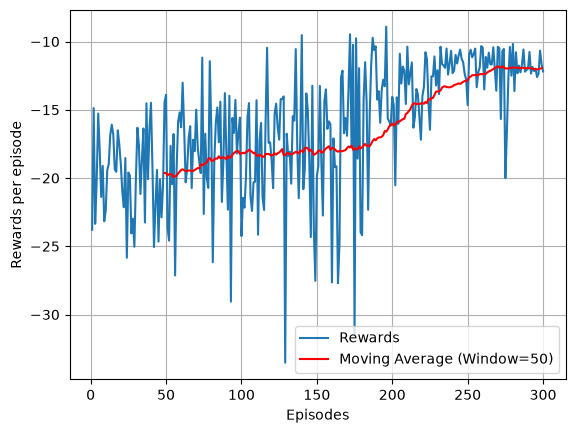

Smoke run done: 300 episodes, last 50 mean return = -11.94


In [10]:
SEED = 0

agent = AgentDQN(EnergyEnv(), gamma=1.0)
train_returns = agent.train(300, lambda r: False, criterion_episodes=50, seed=SEED)
print(f"Smoke run done: {len(train_returns)} episodes, last 50 mean return = {np.mean(train_returns[-50:]):.2f}")

## 5. Evaluation and baselines

In [11]:
TEST_SEED_OFFSET = 10_000_000

def evaluate(policy, n_episodes=300, weather=None):
    """policy(obs) -> action. Returns mean and std of the episode return."""
    env = EnergyEnv(weather)
    returns = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=TEST_SEED_OFFSET + ep)
        G, done = 0.0, False
        while not done:
            obs, r, done, _, _ = env.step(policy(obs))
            G += r
        returns.append(G)
    return np.mean(returns), np.std(returns)

_rng = np.random.default_rng(0)
def random_policy(obs):
    return int(_rng.integers(n_actions))

def rule_policy(obs):
    solar, load, price, plugged = obs[5], obs[7], obs[8], obs[4]
    battery = 0 if solar > load else (2 if price >= P.PRICE_PEAK else 1)
    ev = 1 if plugged and price < P.PRICE_PEAK else 0
    appliance = 1 if price <= P.PRICE_MIDDAY else 0
    return battery * 4 + ev * 2 + appliance

def greedy_policy_from(agent):
    return lambda obs: int(agent.policy(obs))

rule_mean, rule_std = evaluate(rule_policy)
print(f"Rule-based baseline: {rule_mean:.2f} ± {rule_std:.2f}")

Rule-based baseline: -12.46 ± 0.74


## 6. Main training run

Episode 50000 done: steps = 1200000, rewards = -8.05623032129406       

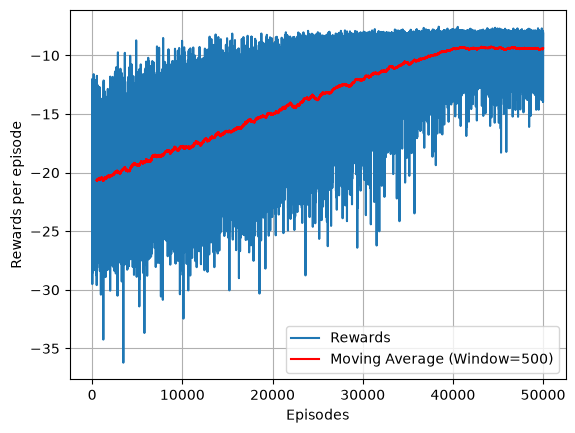

Training time: 1553 s


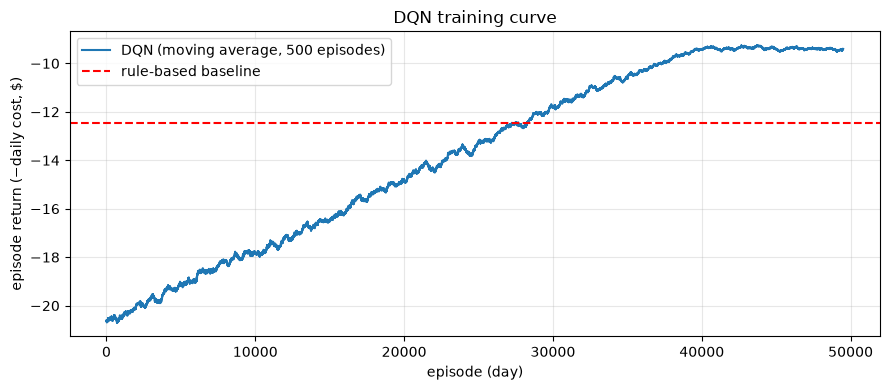

In [12]:
start = time.time()
agent = AgentDQN(EnergyEnv(), gamma=1.0)
train_returns = agent.train(50000, lambda r: False, criterion_episodes=500, seed=SEED)
print(f"Training time: {time.time() - start:.0f} s")

window = 500
moving_avg = np.convolve(train_returns, np.ones(window) / window, mode="valid")
plt.figure(figsize=(9, 4))
plt.plot(moving_avg, label=f"DQN (moving average, {window} episodes)")
plt.axhline(rule_mean, color="r", linestyle="--", label="rule-based baseline")
plt.xlabel("episode (day)"); plt.ylabel("episode return (−daily cost, $)")
plt.title("DQN training curve"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Results: DQN vs baselines, overall and per weather

In [13]:
policies = {"random": random_policy, "rule-based": rule_policy, "DQN": greedy_policy_from(agent)}
print(f"{'policy':<12}" + "".join(f"{w:>16}" for w in ["mixed", "sunny", "cloudy", "rainy"]))
for name, pol in policies.items():
    row = f"{name:<12}"
    for w in [None] + P.WEATHER_TYPES:
        m, s = evaluate(pol, weather=w)
        row += f"{m:>9.2f} ± {s:<4.2f}"
    print(row)

policy                 mixed           sunny          cloudy           rainy
random         -20.83 ± 2.93   -19.95 ± 2.85   -21.47 ± 3.19   -22.66 ± 3.02
rule-based     -12.46 ± 0.74   -12.07 ± 0.38   -12.94 ± 0.24   -14.17 ± 0.29
DQN             -8.85 ± 0.81    -8.27 ± 0.18    -9.52 ± 0.20   -10.75 ± 0.19


## 8. What did the agent learn?
One sunny and one rainy test day, hour by hour, using the greedy policy.

In [14]:
ACTION_NAMES = {"battery": ["charge", "idle", "discharge"], "ev": ["wait", "charge"], "app": ["defer", "start"]}

def show_day(weather, seed=TEST_SEED_OFFSET):
    env = EnergyEnv(weather)
    obs, _ = env.reset(seed=seed)
    print(f"--- {weather} day ---")
    print("hour | battery    EV      appliance | batt  EV   | price | reward")
    done, total = False, 0.0
    while not done:
        a = int(agent.policy(obs))
        b, ev, ap = decode_action(a)
        price = obs[8]
        obs, r, done, _, info = env.step(a)
        total += r
        print(f" {info['hour']:02d}  | {ACTION_NAMES['battery'][b]:<10} {ACTION_NAMES['ev'][ev]:<7} {ACTION_NAMES['app'][ap]:<9} "
              f"| {obs[2]:.2f}  {obs[3]:.2f} | {price:.2f}  | {r:6.2f}")
    print(f"Total return: {total:.2f}\n")

show_day("sunny")
show_day("rainy")

--- sunny day ---
hour | battery    EV      appliance | batt  EV   | price | reward
 07  | idle       wait    defer     | 0.50  0.40 | 0.25  |   0.01
 08  | idle       wait    start     | 0.50  0.40 | 0.25  |   0.01
 09  | idle       wait    start     | 0.50  0.40 | 0.10  |   0.03
 10  | idle       charge  defer     | 0.50  0.40 | 0.10  |   0.07
 11  | idle       charge  defer     | 0.50  0.40 | 0.10  |   0.10
 12  | idle       charge  defer     | 0.50  0.40 | 0.10  |   0.13
 13  | charge     charge  defer     | 0.98  0.40 | 0.10  |  -0.13
 14  | charge     wait    start     | 1.00  0.40 | 0.10  |   0.11
 15  | idle       charge  defer     | 1.00  0.40 | 0.55  |   0.09
 16  | idle       charge  defer     | 1.00  0.40 | 0.55  |   0.06
 17  | idle       wait    defer     | 1.00  0.40 | 0.55  |  -0.30
 18  | discharge  wait    start     | 0.50  0.40 | 0.55  |   0.08
 19  | idle       wait    defer     | 0.50  0.40 | 0.55  |  -1.02
 20  | idle       wait    defer     | 0.50  0.40 | 0.55  |

## 9. Double DQN

Episode 50000 done: steps = 1200000, rewards = -8.29998032129406       

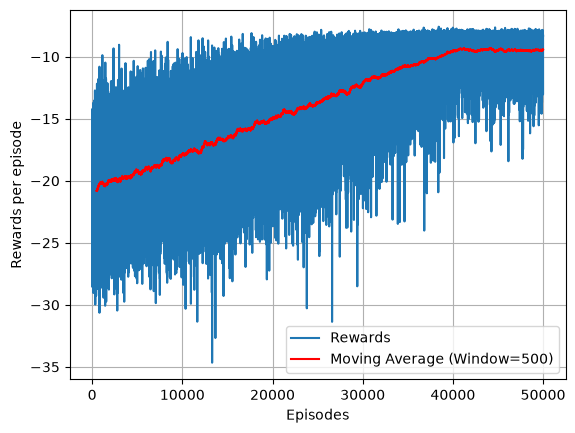

variant        mean return     std
DQN                  -8.85    0.81
Double DQN           -8.92    0.75
rule-based          -12.46    0.74


In [15]:
RUN_DOUBLE = True

dqn_mean, dqn_std = evaluate(greedy_policy_from(agent))
double_mean, double_std = None, None
if RUN_DOUBLE:
    agent_double = AgentDQN(EnergyEnv(), gamma=1.0, double_dqn=True)
    agent_double.train(50000, lambda r: False, criterion_episodes=500, seed=SEED)
    double_mean, double_std = evaluate(greedy_policy_from(agent_double))

print(f"{'variant':<12}{'mean return':>14}{'std':>8}")
print(f"{'DQN':<12}{dqn_mean:>14.2f}{dqn_std:>8.2f}")
if double_mean is not None:
    print(f"{'Double DQN':<12}{double_mean:>14.2f}{double_std:>8.2f}")
print(f"{'rule-based':<12}{rule_mean:>14.2f}{rule_std:>8.2f}")

## 10. Learning rate sweep

Episode 30000 done: steps = 720000, rewards = -8.636191666639018      

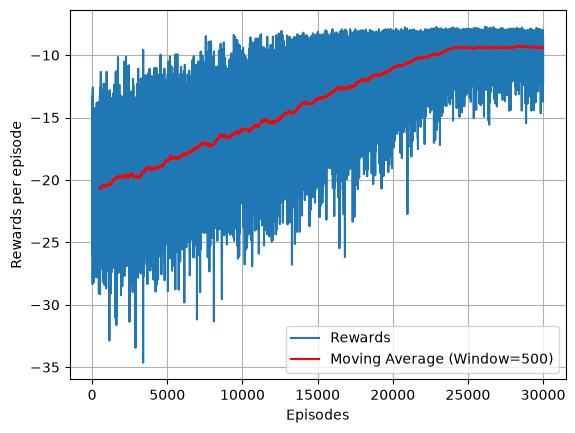

Episode 30000 done: steps = 720000, rewards = -9.496449009032549      

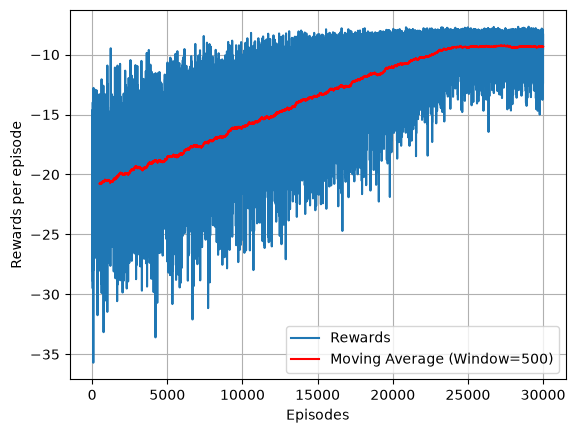

Episode 30000 done: steps = 720000, rewards = -9.010109141281031      

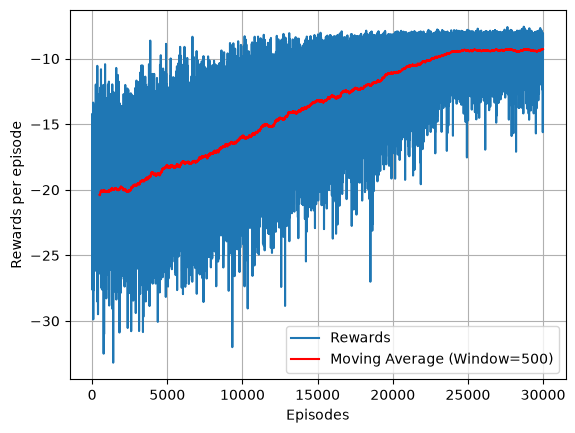

lr = 0.0001 mean return =   -8.90 ± 0.02   (per seed: [-8.88 -8.89 -8.93])
Episode 30000 done: steps = 720000, rewards = -8.636368171718448      

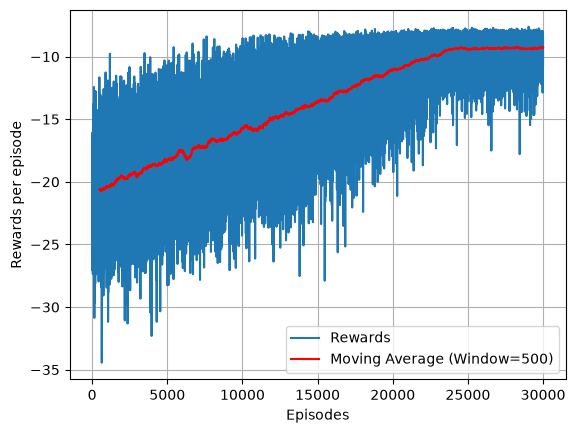

Episode 30000 done: steps = 720000, rewards = -9.484657350676452      

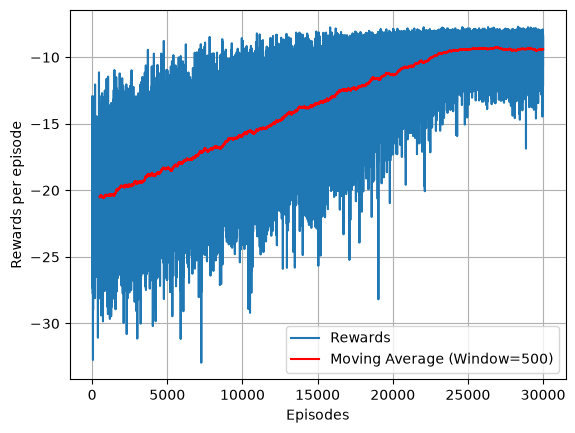

Episode 30000 done: steps = 720000, rewards = -8.149699284194753      

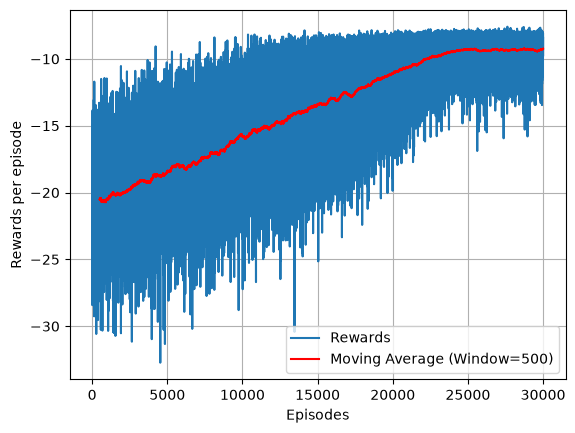

lr = 0.0003 mean return =   -8.86 ± 0.01   (per seed: [-8.86 -8.87 -8.85])
Episode 30000 done: steps = 720000, rewards = -8.698418827839452      

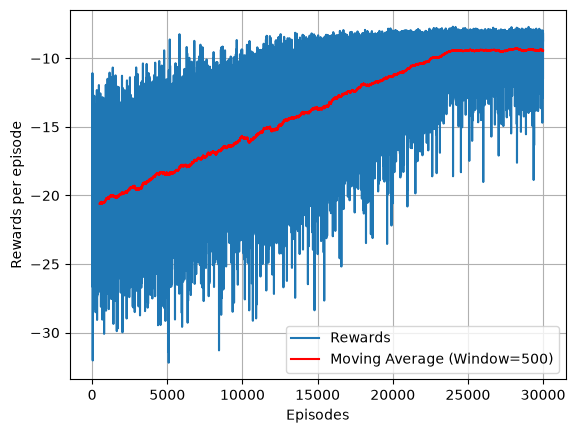

Episode 30000 done: steps = 720000, rewards = -9.412748098227398      

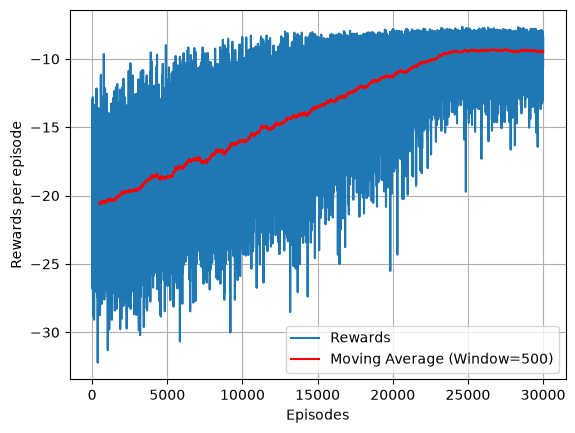

Episode 30000 done: steps = 720000, rewards = -9.113241750768765      

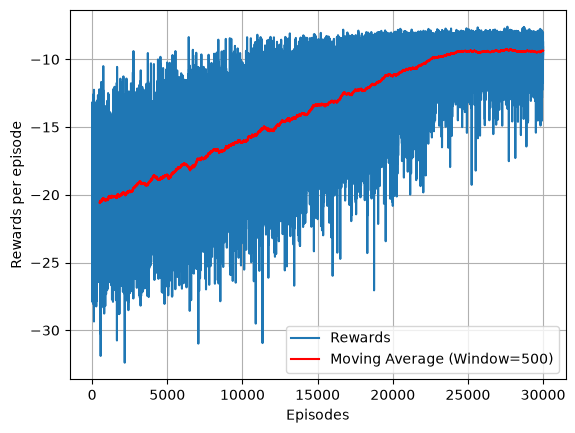

lr = 0.001  mean return =   -8.86 ± 0.02   (per seed: [-8.88 -8.84 -8.87])


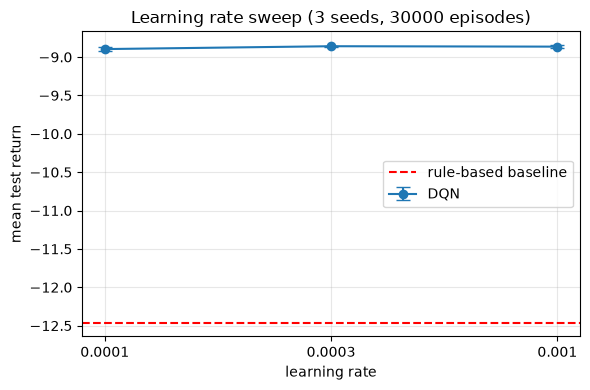

In [16]:
RUN_SWEEP = True
SWEEP_LRS = [1e-4, 3e-4, 1e-3]
SWEEP_SEEDS = [0, 1, 2]
SWEEP_EPISODES = 30000

if RUN_SWEEP:
    sweep_results = {}
    for lr in SWEEP_LRS:
        scores = []
        for seed in SWEEP_SEEDS:
            agent_s = AgentDQN(EnergyEnv(), gamma=1.0, learning_rate=lr)
            agent_s.train(SWEEP_EPISODES, lambda r: False, criterion_episodes=500, seed=seed)
            scores.append(evaluate(greedy_policy_from(agent_s))[0])
        sweep_results[lr] = scores
        print(f"lr = {lr:<6} mean return = {np.mean(scores):7.2f} ± {np.std(scores):.2f}   (per seed: {np.round(scores, 2)})")

    plt.figure(figsize=(6, 4))
    means = [np.mean(sweep_results[lr]) for lr in SWEEP_LRS]
    stds = [np.std(sweep_results[lr]) for lr in SWEEP_LRS]
    plt.errorbar(range(len(SWEEP_LRS)), means, yerr=stds, fmt="o-", capsize=5, label="DQN")
    plt.axhline(rule_mean, color="r", linestyle="--", label="rule-based baseline")
    plt.xticks(range(len(SWEEP_LRS)), SWEEP_LRS)
    plt.xlabel("learning rate"); plt.ylabel("mean test return")
    plt.title(f"Learning rate sweep ({len(SWEEP_SEEDS)} seeds, {SWEEP_EPISODES} episodes)")
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()